# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Suhail Ainur Rofiq | 5054251046 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

# Set random seed agar eksperimen konsisten
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Gunakan GPU jika tersedia, jika tidak gunakan CPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device yang digunakan: {device}")

Device yang digunakan: cpu


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.
df_train = pd.read_csv('fashion-mnist_train.csv')
df_test = pd.read_csv('fashion-mnist_test.csv')

print(f"Ukuran data train : {df_train.shape}")
print(f"Ukuran data test  : {df_test.shape}")
df_train.head()

Ukuran data train : (60000, 785)
Ukuran data test  : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,119,114,130,76,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,33,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


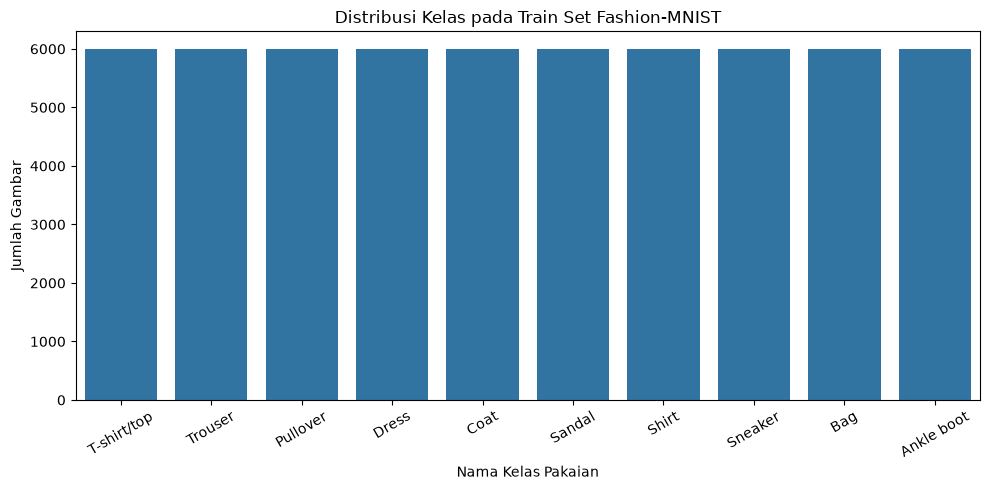

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# Visualisasi jumlah data setiap kelas pada train set
plt.figure(figsize=(10, 5))
sns.countplot(x=df_train['label'].map(lambda x: class_names[x]), order=class_names)
plt.title('Distribusi Kelas pada Train Set Fashion-MNIST')
plt.xlabel('Nama Kelas Pakaian')
plt.ylabel('Jumlah Gambar')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

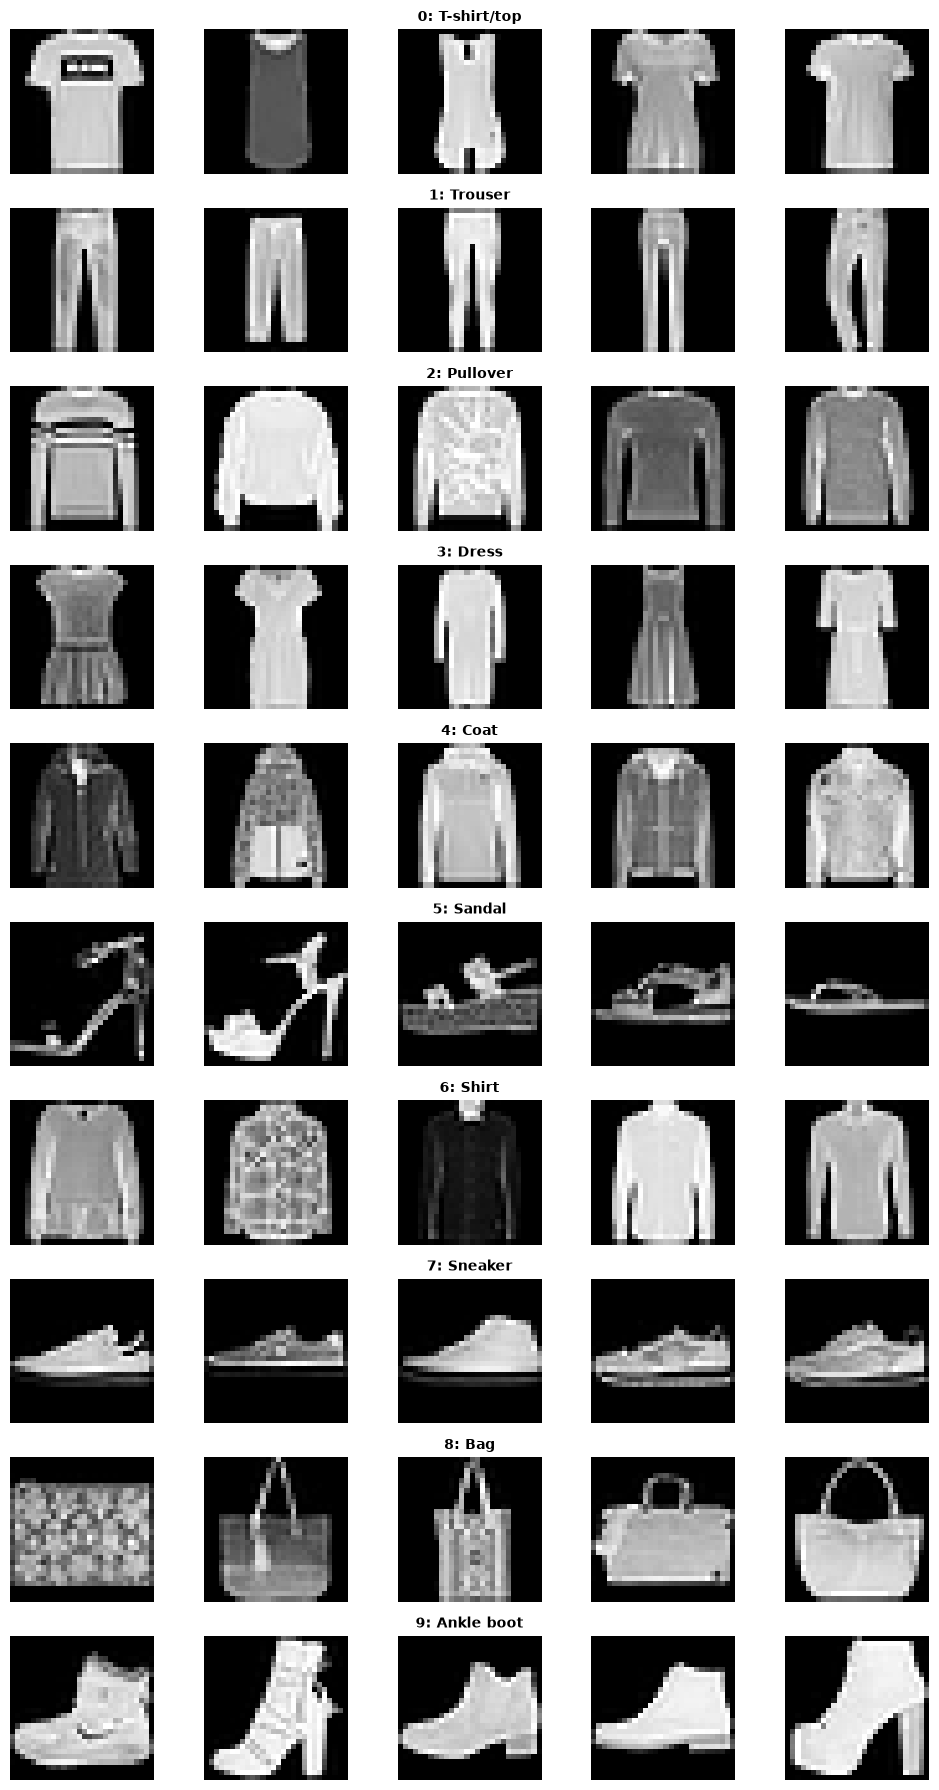

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?
fig, axes = plt.subplots(10, 5, figsize=(10, 18))

for cls_idx, cls_name in enumerate(class_names):
    samples = df_train[df_train['label'] == cls_idx].iloc[:5, 1:].values
    for j in range(5):
        ax = axes[cls_idx, j]
        ax.imshow(samples[j].reshape(28, 28), cmap='gray')
        ax.axis('off')
        if j == 2:
            ax.set_title(f"{cls_idx}: {cls_name}", fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

# Kelas yang terlihat mirip secara visual: T-shirt/top, Shirt, Pullover, dan Coat (sama-sama pakaian atasan berlengan)

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Missing values train: 0
Missing values test : 0


Rentang piksel train: 0 s.d. 255
Distribusi kelas test set:
label
T-shirt/top    1000
Trouser        1000
Pullover       1000
Dress          1000
Coat           1000
Sandal         1000
Shirt          1000
Sneaker        1000
Bag            1000
Ankle boot     1000
Name: count, dtype: int64


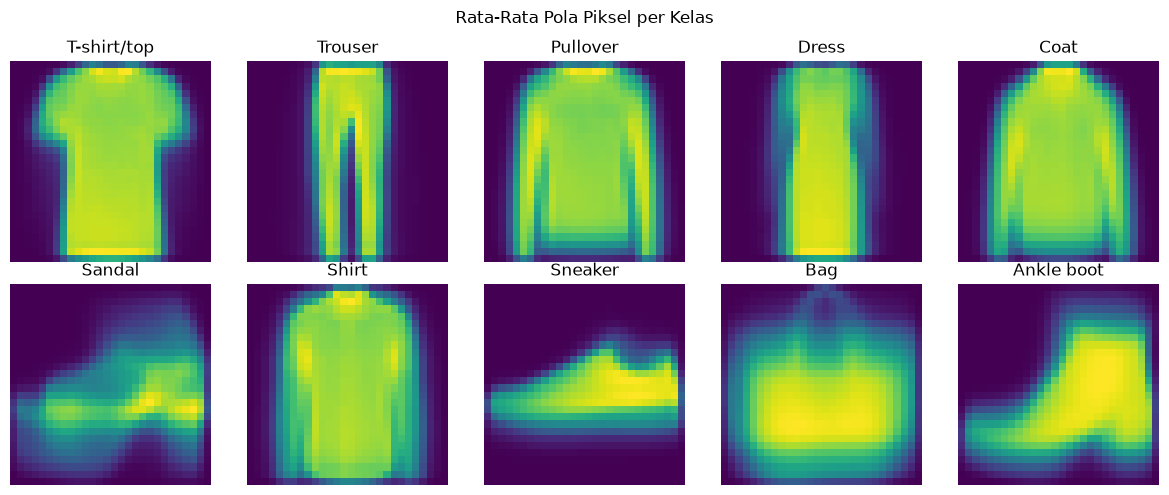

In [5]:
# Cek missing value, rentang nilai piksel, serta distribusi kelas pada test set
print("Missing values train:", df_train.isnull().sum().sum())
print("Missing values test :", df_test.isnull().sum().sum())
print("Rentang piksel train:", df_train.iloc[:, 1:].values.min(), "s.d.", df_train.iloc[:, 1:].values.max())
print("Distribusi kelas test set:")
print(df_test['label'].value_counts().sort_index().rename(index=lambda i: class_names[i]))

# Visualisasi rata-rata gambar (mean image) untuk setiap kelas
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for idx, ax in enumerate(axes.flatten()):
    mean_img = df_train[df_train['label'] == idx].iloc[:, 1:].values.mean(axis=0).reshape(28, 28)
    ax.imshow(mean_img, cmap='viridis')
    ax.set_title(class_names[idx])
    ax.axis('off')

plt.suptitle('Rata-Rata Pola Piksel per Kelas', fontsize=12)
plt.tight_layout()
plt.show()

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
X_train_full = df_train.drop(columns=['label']).values
y_train_full = df_train['label'].values

X_test = df_test.drop(columns=['label']).values
y_test = df_test['label'].values

print(f"X_train_full: {X_train_full.shape}, y_train_full: {y_train_full.shape}")
print(f"X_test      : {X_test.shape}, y_test      : {y_test.shape}")

X_train_full: (60000, 784), y_train_full: (60000,)
X_test      : (10000, 784), y_test      : (10000,)


In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

print(f"Rentang piksel setelah normalisasi -> min: {X_train_full.min()}, max: {X_train_full.max()}")

Rentang piksel setelah normalisasi -> min: 0.0, max: 1.0


In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.10,
    random_state=42,
    stratify=y_train_full
)

print(f"Train set: {X_train.shape}, Val set: {X_val.shape}, Test set: {X_test.shape}")

Train set: (54000, 784), Val set: (6000, 784), Test set: (10000, 784)


In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).
X_train_tensor = torch.tensor(X_train, dtype=torch.float32).reshape(-1, 1, 28, 28)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val, dtype=torch.float32).reshape(-1, 1, 28, 28)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32).reshape(-1, 1, 28, 28)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

batch_size = 128
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_tensor, y_val_tensor), batch_size=batch_size, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_tensor, y_test_tensor), batch_size=batch_size, shuffle=False)

print(f"Bentuk tensor train : {X_train_tensor.shape}")
print(f"Jumlah batch        : train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}")

Bentuk tensor train : torch.Size([54000, 1, 28, 28])
Jumlah batch        : train=422, val=47, test=79


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).
class BaselineANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

model_ann = BaselineANN().to(device)
params_ann = sum(p.numel() for p in model_ann.parameters())
print(model_ann)
print(f"Total parameter ANN: {params_ann:,}")

BaselineANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Total parameter ANN: 235,146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

# Fungsi evaluasi satu loader untuk dipakai saat validasi dan tes
def evaluate_loader(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x_b, y_b in loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            outputs = model(x_b)
            loss = criterion(outputs, y_b)
            total_loss += loss.item() * x_b.size(0)
            correct += (outputs.argmax(dim=1) == y_b).sum().item()
            total += y_b.size(0)
    return total_loss / total, correct / total

# Fungsi training loop reusable untuk semua model
def train_model(model, train_loader, val_loader, criterion, optimizer, device, epochs=10):
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    
    for epoch in range(epochs):
        # 1. Fase training
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            outputs = model(x_b)
            loss = criterion(outputs, y_b)
            loss.backward()
            optimizer.step()
            
            total_loss += loss.item() * x_b.size(0)
            correct += (outputs.argmax(dim=1) == y_b).sum().item()
            total += y_b.size(0)
            
        loss_tr = total_loss / total
        acc_tr = correct / total
        
        # 2. Fase validasi (model.eval & torch.no_grad)
        loss_val, acc_val = evaluate_loader(model, val_loader, criterion, device)
        
        history['train_loss'].append(loss_tr)
        history['val_loss'].append(loss_val)
        history['train_acc'].append(acc_tr)
        history['val_acc'].append(acc_val)
        
        print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {loss_tr:.4f}, Acc: {acc_tr:.4f} | Val Loss: {loss_val:.4f}, Acc: {acc_val:.4f}")
        
    return history

# Jalankan pelatihan ANN Baseline
epochs = 10
criterion = nn.CrossEntropyLoss()
optimizer_ann = torch.optim.Adam(model_ann.parameters(), lr=0.001)

history_ann = train_model(model_ann, train_loader, val_loader, criterion, optimizer_ann, device, epochs=epochs)

Epoch 01/10 | Train Loss: 0.5873, Acc: 0.7937 | Val Loss: 0.4083, Acc: 0.8570


Epoch 02/10 | Train Loss: 0.4017, Acc: 0.8555 | Val Loss: 0.3630, Acc: 0.8675


Epoch 03/10 | Train Loss: 0.3558, Acc: 0.8700 | Val Loss: 0.3580, Acc: 0.8700


Epoch 04/10 | Train Loss: 0.3250, Acc: 0.8808 | Val Loss: 0.3245, Acc: 0.8798


Epoch 05/10 | Train Loss: 0.3042, Acc: 0.8877 | Val Loss: 0.3095, Acc: 0.8873


Epoch 06/10 | Train Loss: 0.2936, Acc: 0.8918 | Val Loss: 0.3168, Acc: 0.8808


Epoch 07/10 | Train Loss: 0.2776, Acc: 0.8974 | Val Loss: 0.2877, Acc: 0.8922


Epoch 08/10 | Train Loss: 0.2638, Acc: 0.9019 | Val Loss: 0.2891, Acc: 0.8945


Epoch 09/10 | Train Loss: 0.2549, Acc: 0.9050 | Val Loss: 0.2835, Acc: 0.8970


Epoch 10/10 | Train Loss: 0.2429, Acc: 0.9096 | Val Loss: 0.2814, Acc: 0.8985


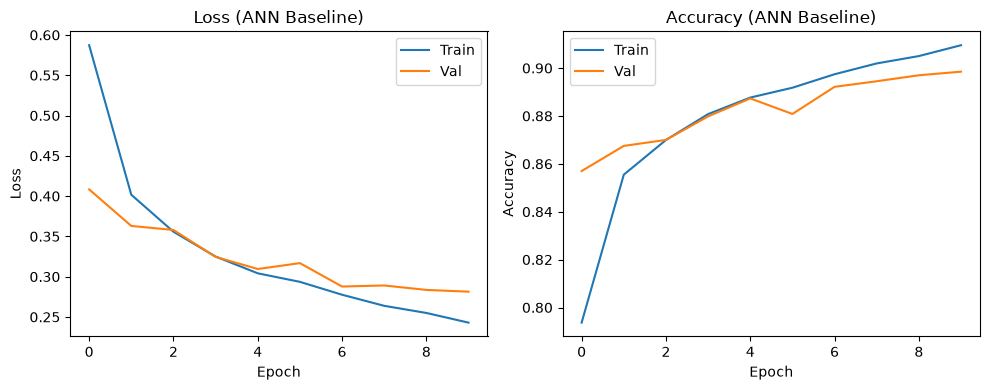

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.
def plot_learning_curve(history, title):
    plt.figure(figsize=(10, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train')
    plt.plot(history['val_loss'], label='Val')
    plt.title(f'Loss ({title})')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history['train_acc'], label='Train')
    plt.plot(history['val_acc'], label='Val')
    plt.title(f'Accuracy ({title})')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    
    plt.tight_layout()
    plt.show()

plot_learning_curve(history_ann, 'ANN Baseline')

In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.
def predict_model(model, loader, device):
    model.eval()
    preds_list = []
    with torch.no_grad():
        for x_b, _ in loader:
            x_b = x_b.to(device)
            outputs = model(x_b)
            preds_list.append(outputs.argmax(dim=1).cpu().numpy())
    return np.concatenate(preds_list)

y_pred_ann = predict_model(model_ann, test_loader, device)
print("5 Prediksi Pertama ANN:", [class_names[i] for i in y_pred_ann[:5]])

5 Prediksi Pertama ANN: ['Ankle boot', 'Pullover', 'Trouser', 'Trouser', 'Shirt']


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

# Perhitungan manual dimensi output dengan rumus (W - K + 2P) / S + 1:
# Input awal      : (1, 28, 28)
# 1. Conv2d(3,P=1): (28 - 3 + 2*1)/1 + 1 = 28 -> output (32, 28, 28)
# 2. MaxPool2d(2) : (28 - 2 + 0)/2 + 1   = 14 -> output (32, 14, 14)
# 3. Conv2d(3,P=1): (14 - 3 + 2*1)/1 + 1 = 14 -> output (64, 14, 14)
# 4. MaxPool2d(2) : (14 - 2 + 0)/2 + 1   = 7  -> output (64, 7, 7)
# Flatten         : 64 * 7 * 7 = 3136 fitur masuk ke Linear(3136, 128)

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model_cnn = SimpleCNN().to(device)
params_cnn = sum(p.numel() for p in model_cnn.parameters())
print(model_cnn)
print(f"Total parameter Simple CNN: {params_cnn:,}")

# Verifikasi dimensi output konvolusi menggunakan dummy tensor
dummy = torch.zeros(1, 1, 28, 28).to(device)
dummy_out = model_cnn.features(dummy)
print(f"Bentuk output konvolusi (dummy): {dummy_out.shape} -> Flatten: {dummy_out.numel()}")

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Total parameter Simple CNN: 421,642
Bentuk output konvolusi (dummy): torch.Size([1, 64, 7, 7]) -> Flatten: 3136


Epoch 01/10 | Train Loss: 0.5324, Acc: 0.8085 | Val Loss: 0.4457, Acc: 0.8278


Epoch 02/10 | Train Loss: 0.3331, Acc: 0.8807 | Val Loss: 0.2985, Acc: 0.8908


Epoch 03/10 | Train Loss: 0.2832, Acc: 0.8973 | Val Loss: 0.2487, Acc: 0.9117


Epoch 04/10 | Train Loss: 0.2510, Acc: 0.9077 | Val Loss: 0.2499, Acc: 0.9068


Epoch 05/10 | Train Loss: 0.2282, Acc: 0.9166 | Val Loss: 0.2150, Acc: 0.9208


Epoch 06/10 | Train Loss: 0.2106, Acc: 0.9225 | Val Loss: 0.2185, Acc: 0.9178


Epoch 07/10 | Train Loss: 0.1918, Acc: 0.9291 | Val Loss: 0.2041, Acc: 0.9212


Epoch 08/10 | Train Loss: 0.1715, Acc: 0.9366 | Val Loss: 0.2064, Acc: 0.9240


Epoch 09/10 | Train Loss: 0.1585, Acc: 0.9417 | Val Loss: 0.1961, Acc: 0.9285


Epoch 10/10 | Train Loss: 0.1441, Acc: 0.9467 | Val Loss: 0.2131, Acc: 0.9240


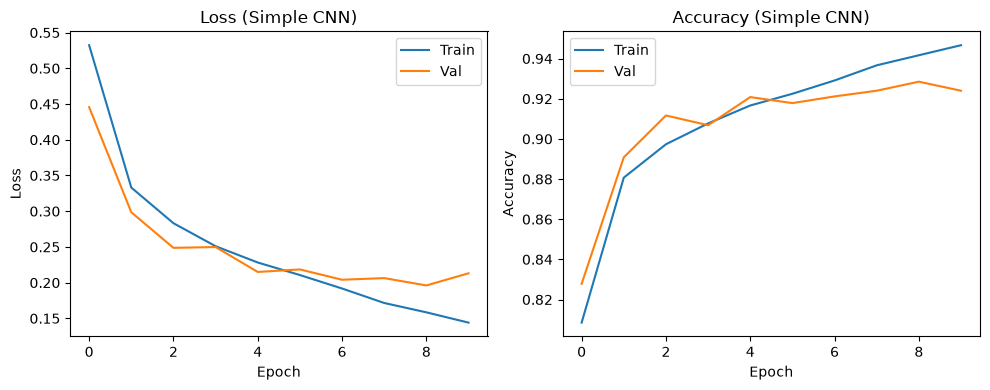

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.
optimizer_cnn = torch.optim.Adam(model_cnn.parameters(), lr=0.001)
history_cnn = train_model(model_cnn, train_loader, val_loader, criterion, optimizer_cnn, device, epochs=epochs)
plot_learning_curve(history_cnn, 'Simple CNN')

In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_cnn = predict_model(model_cnn, test_loader, device)
print("5 Prediksi Pertama Simple CNN:", [class_names[i] for i in y_pred_cnn[:5]])

5 Prediksi Pertama Simple CNN: ['Ankle boot', 'Pullover', 'Trouser', 'Trouser', 'Shirt']


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.
class CNNBatchNormDropout(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model_cnn_bn = CNNBatchNormDropout().to(device)
params_cnn_bn = sum(p.numel() for p in model_cnn_bn.parameters())
print(model_cnn_bn)
print(f"Total parameter CNN + BN + Dropout: {params_cnn_bn:,}")

CNNBatchNormDropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Total parameter CNN + BN + Dropout: 421,834


Epoch 01/10 | Train Loss: 0.4578, Acc: 0.8347 | Val Loss: 0.2815, Acc: 0.8965


Epoch 02/10 | Train Loss: 0.3112, Acc: 0.8870 | Val Loss: 0.2539, Acc: 0.9037


Epoch 03/10 | Train Loss: 0.2719, Acc: 0.9002 | Val Loss: 0.2345, Acc: 0.9125


Epoch 04/10 | Train Loss: 0.2424, Acc: 0.9112 | Val Loss: 0.2146, Acc: 0.9197


Epoch 05/10 | Train Loss: 0.2223, Acc: 0.9181 | Val Loss: 0.2266, Acc: 0.9167


Epoch 06/10 | Train Loss: 0.2055, Acc: 0.9230 | Val Loss: 0.2092, Acc: 0.9245


Epoch 07/10 | Train Loss: 0.1919, Acc: 0.9288 | Val Loss: 0.2203, Acc: 0.9223


Epoch 08/10 | Train Loss: 0.1779, Acc: 0.9331 | Val Loss: 0.2268, Acc: 0.9158


Epoch 09/10 | Train Loss: 0.1670, Acc: 0.9387 | Val Loss: 0.1910, Acc: 0.9322


Epoch 10/10 | Train Loss: 0.1530, Acc: 0.9425 | Val Loss: 0.2040, Acc: 0.9302


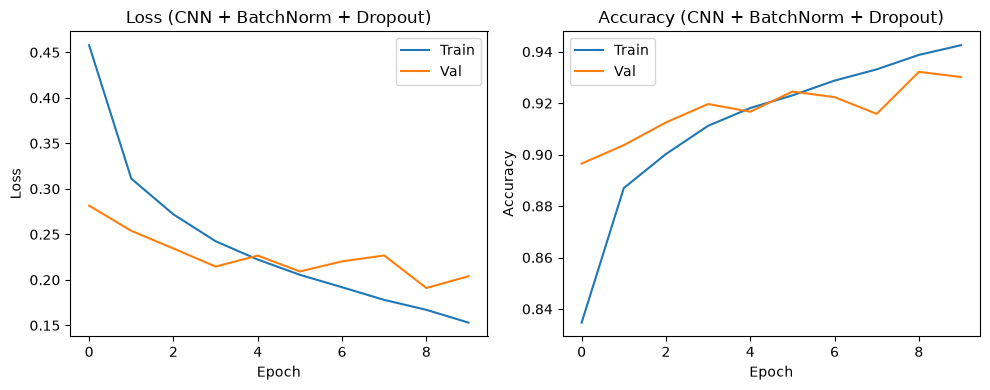

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.
optimizer_cnn_bn = torch.optim.Adam(model_cnn_bn.parameters(), lr=0.001)
history_cnn_bn = train_model(model_cnn_bn, train_loader, val_loader, criterion, optimizer_cnn_bn, device, epochs=epochs)
plot_learning_curve(history_cnn_bn, 'CNN + BatchNorm + Dropout')

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_cnn_bn = predict_model(model_cnn_bn, test_loader, device)
print("5 Prediksi Pertama CNN + BN + Dropout:", [class_names[i] for i in y_pred_cnn_bn[:5]])

5 Prediksi Pertama CNN + BN + Dropout: ['Ankle boot', 'Pullover', 'Trouser', 'Trouser', 'Shirt']


# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.
model_configs = [
    ('ANN (Baseline)', model_ann, y_pred_ann, params_ann),
    ('CNN Sederhana', model_cnn, y_pred_cnn, params_cnn),
    ('CNN + BatchNorm + Dropout', model_cnn_bn, y_pred_cnn_bn, params_cnn_bn)
]

eval_data = []
for name, mdl, pred, n_params in model_configs:
    eval_data.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (Macro)': precision_score(y_test, pred, average='macro'),
        'Recall (Macro)': recall_score(y_test, pred, average='macro'),
        'F1-Score (Macro)': f1_score(y_test, pred, average='macro'),
        'Jumlah Parameter': n_params
    })

df_eval = pd.DataFrame(eval_data)

# Pilih model terbaik berdasarkan F1-Score Macro tertinggi
best_idx = df_eval['F1-Score (Macro)'].idxmax()
best_name, best_model, best_pred, _ = model_configs[best_idx]
print(f"Model Terbaik: {best_name}")
df_eval

Model Terbaik: CNN Sederhana


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Jumlah Parameter
0,ANN (Baseline),0.8838,0.884261,0.8838,0.882804,235146
1,CNN Sederhana,0.9193,0.920664,0.9193,0.918813,421642
2,CNN + BatchNorm + Dropout,0.9184,0.919457,0.9184,0.918079,421834


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.
print(f"Classification Report - {best_name}:\n")
print(classification_report(y_test, best_pred, target_names=class_names, digits=4))

Classification Report - CNN Sederhana:

              precision    recall  f1-score   support

 T-shirt/top     0.8177    0.9240    0.8676      1000
     Trouser     0.9890    0.9890    0.9890      1000
    Pullover     0.9273    0.8160    0.8681      1000
       Dress     0.9298    0.9270    0.9284      1000
        Coat     0.8267    0.9110    0.8668      1000
      Sandal     0.9726    0.9940    0.9832      1000
       Shirt     0.8082    0.7250    0.7644      1000
     Sneaker     0.9549    0.9730    0.9638      1000
         Bag     0.9919    0.9830    0.9874      1000
  Ankle boot     0.9886    0.9510    0.9694      1000

    accuracy                         0.9193     10000
   macro avg     0.9207    0.9193    0.9188     10000
weighted avg     0.9207    0.9193    0.9188     10000



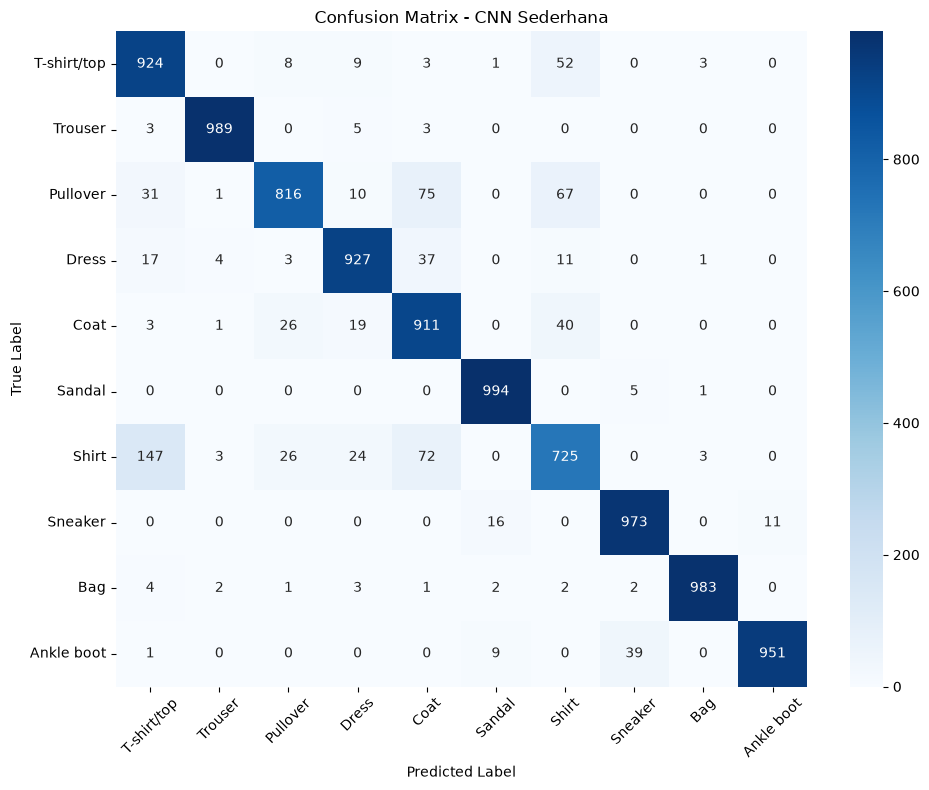

5 Pasangan kelas paling sering tertukar (True -> Predicted):
  Shirt        -> T-shirt/top  : 147 gambar
  Pullover     -> Coat         : 75 gambar
  Shirt        -> Coat         : 72 gambar
  Pullover     -> Shirt        : 67 gambar
  T-shirt/top  -> Shirt        : 52 gambar


In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?
cm = confusion_matrix(y_test, best_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - {best_name}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Cari 5 pasangan kelas (di luar diagonal) yang paling sering tertukar
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
pairs = []
for i in range(10):
    for j in range(10):
        if cm_off[i, j] > 0:
            pairs.append((cm_off[i, j], class_names[i], class_names[j]))
pairs.sort(reverse=True)
print("5 Pasangan kelas paling sering tertukar (True -> Predicted):")
for count, t_cls, p_cls in pairs[:5]:
    print(f"  {t_cls:12s} -> {p_cls:12s} : {count} gambar")

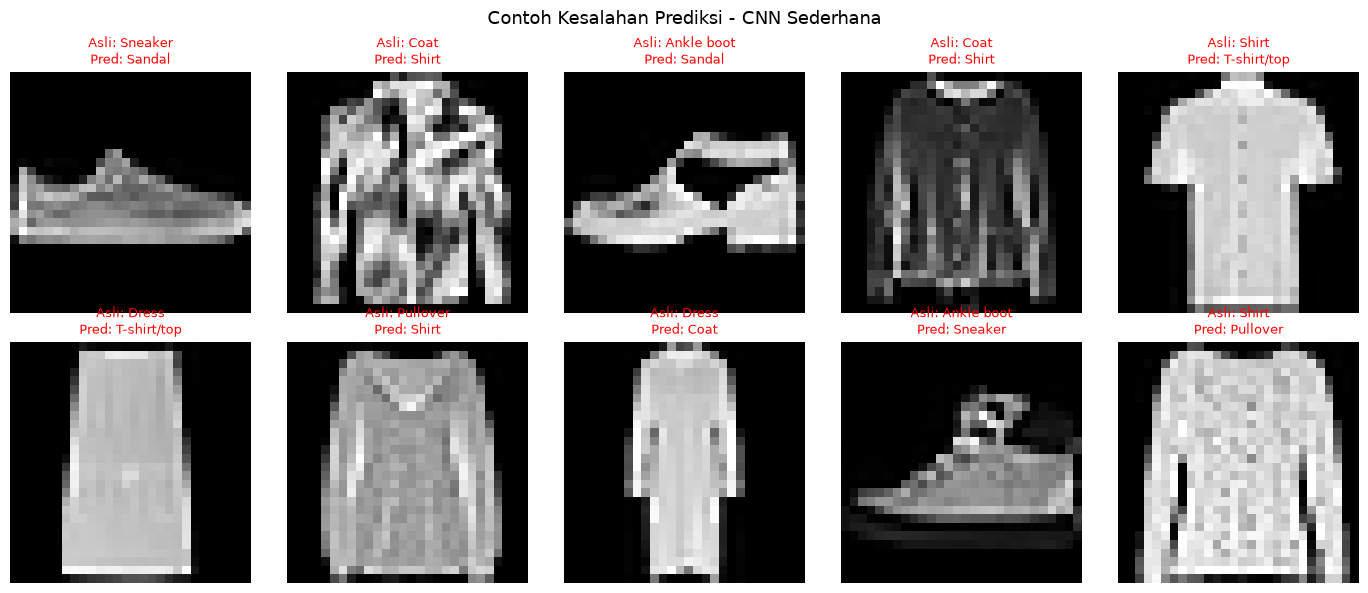

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.
wrong_idx = np.where(best_pred != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flatten()):
    idx = wrong_idx[i]
    img = X_test[idx].reshape(28, 28)
    ax.imshow(img, cmap='gray')
    ax.set_title(f"Asli: {class_names[y_test[idx]]}\nPred: {class_names[best_pred[idx]]}", color='red', fontsize=9)
    ax.axis('off')

plt.suptitle(f'Contoh Kesalahan Prediksi - {best_name}', fontsize=13)
plt.tight_layout()
plt.show()

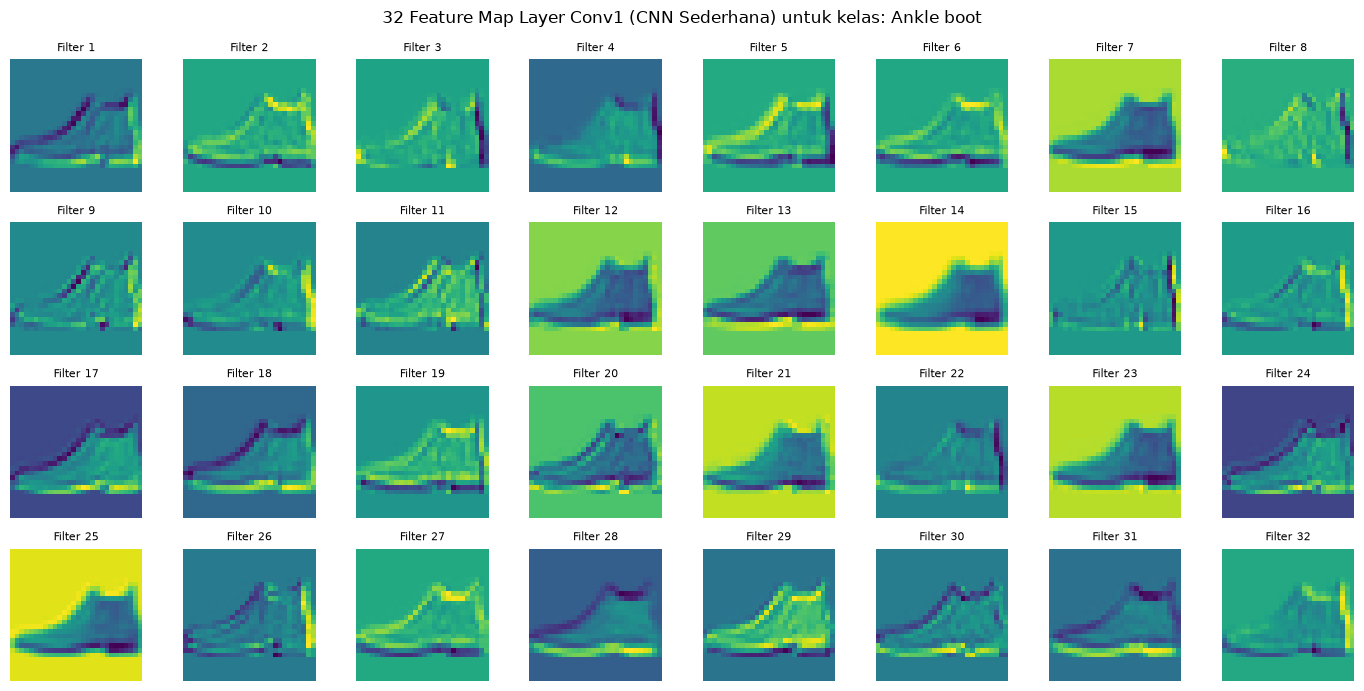

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

# Ambil satu contoh gambar dari test set (misalnya Ankle boot / gambar indeks 0)
sample_img = X_test_tensor[0:1].to(device)

# Lewatkan hanya ke layer konvolusi pertama (features[0])
best_model.eval()
with torch.no_grad():
    fmap = best_model.features[0](sample_img).squeeze(0).detach().cpu().numpy()

fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(fmap[i], cmap='viridis')
    ax.set_title(f'Filter {i+1}', fontsize=8)
    ax.axis('off')

plt.suptitle(f'32 Feature Map Layer Conv1 ({best_name}) untuk kelas: {class_names[y_test[0]]}', fontsize=12)
plt.tight_layout()
plt.show()

In [25]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.
import os

torch.save(best_model.state_dict(), "model.pth")
print(f"Bobot model terbaik ({best_name}) berhasil disimpan ke 'model.pth'!")
print(f"Ukuran file model.pth: {os.path.getsize('model.pth') / 1024:.2f} KB")

Bobot model terbaik (CNN Sederhana) berhasil disimpan ke 'model.pth'!
Ukuran file model.pth: 1650.30 KB


# 5. Analisis

### 1. Perbandingan Performa Model (ANN vs CNN Sederhana vs CNN + BatchNorm + Dropout)
Berdasarkan hasil pengujian pada 10.000 gambar test set, berikut perbandingan performa ketiga model:

1. ANN (Baseline): Mencapai Accuracy 88.38 persen dengan F1-Score (Macro) 0.8828 dan memiliki 235.146 parameter. Performa ini sudah cukup baik untuk model dasar, namun paling rendah di antara ketiga model.
2. CNN Sederhana: Mengalami lonjakan performa yang signifikan dengan Accuracy 91.93 persen dan F1-Score (Macro) 0.9188 (selisih lebih tinggi 3.55 persen dari ANN). Model ini memiliki 421.642 parameter dan menjadi model dengan skor tertinggi pada test set kali ini.
3. CNN + BatchNorm + Dropout: Memperoleh Accuracy 91.84 persen dan F1-Score (Macro) 0.9181 dengan 421.834 parameter. Selisihnya sangat tipis (hanya 0.09 persen) di bawah CNN Sederhana pada test set, namun justru memperoleh akurasi validasi yang lebih tinggi selama masa training (mencapai 93.22 persen di epoch 9 dan 93.02 persen di epoch 10, dibanding CNN Sederhana sebesar 92.40 persen).

### 2. Pengaruh Jumlah Parameter dan Cara Kerja Model Memproses Gambar
1. Mengapa CNN jauh mengungguli ANN? ANN langsung meratakan gambar 28x28 menjadi satu baris vektor berisi 784 angka melalui nn.Flatten(). Cara ini membuat ANN kehilangan informasi posisi spasial antar piksel yang berdekatan (seperti bentuk lengkungan kerah, garis lengan, atau sol sepatu). Sebaliknya, CNN memindai gambar secara dua dimensi menggunakan filter berukuran 3x3 pada layer konvolusi sehingga mampu mengenali pola garis tepi, sudut, dan tekstur pakaian sebelum dirangkum ke layer Linear.
2. Komposisi Parameter: Pada model ANN, hampir seluruh parameter habis dipakai di layer pertama Linear(784, 256) sebanyak 200.960 parameter. Pada model CNN, bagian pengekstrak fitur (dua layer Conv2d) sebenarnya sangat hemat karena hanya menggunakan 18.816 parameter, sedangkan sebagian besar dari 421 ribu parameter berada di layer classifier Linear(3136, 128). Penambahan BatchNorm2d pada model ketiga hanya menambah 192 parameter saja (dari 421.642 menjadi 421.834), tetapi memberikan dampak stabilitas yang besar.

### 3. Pengaruh Batch Normalization dan Dropout terhadap Learning Curve
1. Kecepatan Konvergensi Awal: Pada Epoch 1, CNN + BatchNorm + Dropout langsung mencatat akurasi validasi 89.65 persen (Val Loss 0.2815), jauh lebih cepat dibanding CNN Sederhana yang baru mencapai 82.78 persen (Val Loss 0.4457). Batch Normalization membantu menormalkan distribusi nilai fitur di setiap batch sehingga proses optimasi berjalan lebih cepat dan stabil.
2. Pengendalian Overfitting: Di akhir epoch ke-10 pada CNN Sederhana, akurasi train mencapai 94.67 persen sementara akurasi validasi berada di 92.40 persen (selisih jarak 2.27 persen), dan Val Loss mulai sedikit naik dari 0.1961 menjadi 0.2131. Pada CNN + BatchNorm + Dropout, selisih akurasi train dan validasi lebih kecil, yaitu hanya 1.23 persen (Train 94.25 persen vs Val 93.02 persen). Ini membuktikan bahwa kombinasi Dropout 0.3 dan BatchNorm berhasil menahan laju overfitting agar kemampuan generalisasi model tetap terjaga. Dalam 10 epoch, efek regularisasi Dropout memang membuat proses fitting di data test sedikit tertahan sehingga hasilnya hampir berimbang dengan CNN Sederhana.

### 4. Kelas yang Mudah dan Sulit Dibedakan serta Analisis Feature Map
1. Kelas yang Sangat Akurat: Model terbaik (CNN Sederhana) sangat mudah mengenali kelas dengan bentuk siluet khas, seperti Trouser (F1 0.9890), Bag (F1 0.9874), Sandal (F1 0.9832), Ankle boot (F1 0.9694), dan Sneaker (F1 0.9638).
2. Kelas yang Paling Sering Tertukar: Berdasarkan Confusion Matrix 10x10 dan Classification Report, kelas tersulit adalah Shirt dengan F1-Score paling rendah (0.7644) dan Recall 72.50 persen. Lima pasangan kesalahan tertinggi adalah Shirt tertukar menjadi T-shirt/top (147 gambar), Pullover menjadi Coat (75 gambar), Shirt menjadi Coat (72 gambar), Pullover menjadi Shirt (67 gambar), dan T-shirt/top menjadi Shirt (52 gambar). Hal ini wajar karena keempat kelas tersebut sama-sama merupakan pakaian atasan berlengan dengan siluet hampir identik pada resolusi gambar kecil 28x28 piksel, sehingga detail halus seperti kerah atau kancing sulit dibedakan.
3. Pengamatan Feature Map Conv1: Dari 32 feature map layer konvolusi pertama pada contoh gambar Ankle boot, terlihat masing-masing filter menangkap ciri visual yang berbeda, seperti garis tepi luar sepatu (outline), bagian lekukan tumit, area sol bawah, hingga bagian isi sepatu yang padat.

# 6. Kesimpulan dan Saran

### Kesimpulan
1. Arsitektur Convolutional Neural Network (CNN) terbukti jauh lebih efektif daripada ANN biasa dalam mengklasifikasikan gambar Fashion-MNIST, karena CNN menjaga informasi spasial 2D gambar. Akurasi test set meningkat dari 88.38 persen (ANN) menjadi 91.93 persen (CNN Sederhana) dan 91.84 persen (CNN + BatchNorm + Dropout).
2. Penambahan Batch Normalization dan Dropout terbukti mempercepat proses konvergensi sejak epoch pertama dan memperkecil jarak (gap) overfitting antara training dan validation set.
3. Model terbaik berdasarkan skor test set pada eksperimen 10 epoch ini adalah CNN Sederhana (class SimpleCNN) dengan Accuracy 91.93 persen dan Macro F1-Score 0.9188, dan bobotnya telah disimpan ke file model.pth (1650.30 KB) untuk kebutuhan deployment.
4. Kesalahan klasifikasi model terutama terpusat pada kategori pakaian atasan (Shirt, T-shirt/top, Pullover, dan Coat) akibat kemiripan bentuk siluet pada gambar beresolusi rendah (28x28 piksel).

### Saran
1. Menambah jumlah epoch pelatihan (misalnya 15 sampai 25 epoch) dengan Learning Rate Scheduler dan Early Stopping. Dengan waktu latihan lebih panjang, model CNN + BatchNorm + Dropout berpotensi melampaui CNN Sederhana di test set karena regularisasinya menahan overfitting lebih lama.
2. Menerapkan Data Augmentation (seperti RandomHorizontalFlip atau sedikit pergeseran/rotasi) agar model lebih mampu membedakan detail pakaian atasan yang mirip dan mengurangi kesalahan prediksi pada kelas Shirt.
3. Pada tahap Deployment nanti, pastikan menggunakan definisi class SimpleCNN untuk memuat bobot dari file model.pth agar struktur layer sesuai saat melakukan inferensi.